# Exploratory Data Analysis — AI Tool Discovery & Risk Classification

**Author:** Joshua Hu ([@JoshuaCongHu](https://github.com/JoshuaCongHu))<br>
**Date:** 2026-10-07<br>
**Scope:** EDA of the cleaned Kaggle AI tool metadata, the synthetic enterprise usage logs, and how the two datasets line up, as input for the discovery, categorization and risk-scoring stages.

| Dataset | File | Role (see `VISION.md`) |
|---|---|---|
| Cleaned Kaggle (AIToolBuzz) | `data/cleaned_kaggle.csv` | Raw tool metadata after cleaning (`preprocessing_scripts/cleaned_kaggle.py`) |
| Dataset B (incomplete) | `data/dataset_b_ai_tool_metadata_incomplete.csv` | Kaggle mapped to the AI Tool Metadata schema (`preprocessing_scripts/convert_kaggle.py`) |
| Dataset A: NovaTech | `data/novatech_usage (1).csv` | Synthetic enterprise activity (tech company) |
| Dataset A: Summit Financial | `data/summit_financial_usage (1).csv` | Synthetic enterprise activity (financial company) |

**Contents**
1. Part A: Kaggle tool metadata
2. Part B: Synthetic enterprise usage logs
3. Part C: Cross-dataset (does usage line up with the metadata?)
4. Part D: Key findings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# works whether the notebook is run from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data"

import matplotlib
print(f"pandas {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# chart colors
BLUE = "#2a78d6"     # primary series / AI tools
ORANGE = "#eb6834"   # second series / non-AI tools
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 90,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlecolor": INK,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 9,
})


def barh(series, title, xlabel="count", color=BLUE, ax=None, fmt="{:,.0f}"):
    # horizontal bar chart, biggest at the top, value labels at bar ends
    series = series.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(7, max(2.5, 0.28 * len(series))))
    colors = color if isinstance(color, (list, np.ndarray)) else [color] * len(series)
    ax.barh(series.index.astype(str), series.values, color=colors, height=0.7)
    for y, v in enumerate(series.values):
        ax.text(v, y, " " + fmt.format(v), va="center", fontsize=8, color=MUTED)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    return ax

pandas 3.0.6 | numpy 2.5.3 | matplotlib 3.11.2


---
## Part A: Kaggle tool metadata (`cleaned_kaggle.csv`)

The cleaning step kept only tools with an **Active** website and a non-empty **Short Description**, filled other text columns with `""` and dropped duplicate `(Name, Website)` pairs.

In [2]:
kaggle = pd.read_csv(DATA / "cleaned_kaggle.csv")
raw = pd.read_csv(DATA / "Complete AI Tools Dataset 2025 - 16763 Tools from AIToolBuzz.csv")

print(f"raw rows:     {len(raw):,}")
print(f"cleaned rows: {len(kaggle):,}  ({len(raw) - len(kaggle):,} removed, {1 - len(kaggle) / len(raw):.1%})")
kaggle.dtypes.to_frame("dtype").T

raw rows:     16,762
cleaned rows: 13,701  (3,061 removed, 18.3%)


,Name,Link,Logo,Category,Primary Task,Keywords,Year Founded,Short Description,Country,industry,technologies,Website,Website Status
dtype,str,str,str,str,str,str,float64,str,str,str,str,str,str


In [3]:
kaggle.head(3)

,Name,Link,Logo,Category,Primary Task,Keywords,Year Founded,Short Description,Country,industry,technologies,Website,Website Status
0,ChatGPT,https://aitoolbuzz.com/chatgpt,https://aitoolbuzz.com/tools/logo/chatgpt.jpg,Communication And Support,Automated conversational customer service.,"cybersecurity, web development, ads, it services & it consulting, informatio...",2022.0,ChatGPT is an advanced AI language model by OpenAI that generates human-like...,Estonia,information technology & services,NaN,https://chatgpt.com?ref=aitoolbuzz.com,Active
1,Claude,https://aitoolbuzz.com/claude,https://aitoolbuzz.com/tools/logo/claude.jpg,Operations And Management,Task automation,"artificial intelligence, large language models, machine learning, natural la...",2023.0,Automated assistant handles tasks and talks naturally.,United States,research,Cloudflare DNS,https://claude.ai/?ref=aitoolbuzz.com,Active
2,Google Gemini,https://aitoolbuzz.com/google-gemini,https://aitoolbuzz.com/tools/logo/google-gemini.jpg,Ai And Machine Learning,Large Language Models,NaN,2023.0,Google Gemini is Google DeepMind’s next-generation AI model designed for adv...,NaN,NaN,NaN,https://gemini.google.com?ref=aitoolbuzz.com,Active


### A1. Missing data

`cleaned_kaggle.py` fills missing text with `""`, but CSV round-trips turn `""` back into `NaN` on read, so the counts below are the real share of rows with **no value**.

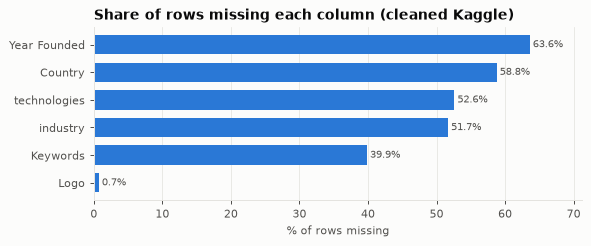

,% missing
Year Founded,63.6
Country,58.8
technologies,52.6
industry,51.7
Keywords,39.9
Logo,0.7


In [4]:
missing = (kaggle.isna().mean() * 100).sort_values(ascending=False)
missing = missing[missing > 0]

ax = barh(missing, "Share of rows missing each column (cleaned Kaggle)", xlabel="% of rows missing", fmt="{:.1f}%")
plt.show()
missing.round(1).to_frame("% missing")

### A2. Category distribution

`Category` is the only categorization label we have, so its balance matters for training a classifier.

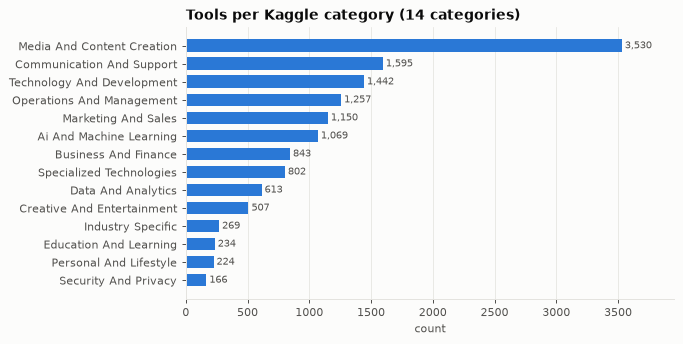

largest / smallest category: 21x


,% of tools
Category,
Media And Content Creation,25.8
Communication And Support,11.6
Technology And Development,10.5
Operations And Management,9.2
Marketing And Sales,8.4
Ai And Machine Learning,7.8
Business And Finance,6.2
Specialized Technologies,5.9
Data And Analytics,4.5


In [5]:
cat_counts = kaggle["Category"].value_counts()
barh(cat_counts, f"Tools per Kaggle category ({cat_counts.size} categories)")
plt.show()

cat_share = (cat_counts / cat_counts.sum() * 100).round(1)
print(f"largest / smallest category: {cat_counts.max() / cat_counts.min():.0f}x")
cat_share.to_frame("% of tools")

### A3. Primary Task

`Primary Task` reads like a finer-grained label. Is it usable as one?

distinct Primary Task values: 2,973
values used by only one tool: 1,769 (60%)
top 20 values cover:          21% of tools


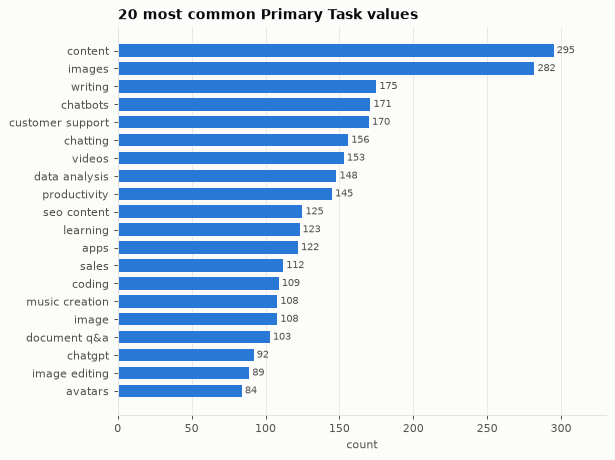

In [6]:
task = kaggle["Primary Task"].str.strip().str.lower()
task_counts = task.value_counts()

print(f"distinct Primary Task values: {task_counts.size:,}")
print(f"values used by only one tool: {(task_counts == 1).sum():,} ({(task_counts == 1).mean():.0%})")
print(f"top 20 values cover:          {task_counts.head(20).sum() / len(task):.0%} of tools")

barh(task_counts.head(20), "20 most common Primary Task values")
plt.show()

### A4. Description length

`Short Description` is the main text feature for embeddings / NLP classification of unseen tools.

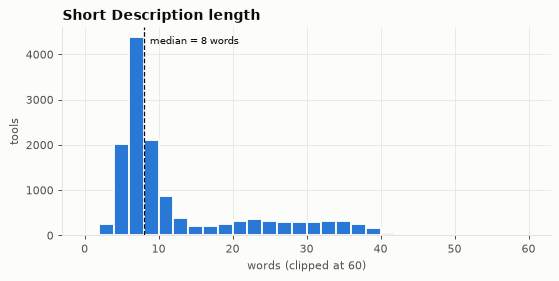

count    13701.0
mean        12.3
std          9.8
min          1.0
25%          6.0
50%          8.0
75%         16.0
max        100.0

descriptions with <= 5 words: 2,288 (17%)


In [7]:
words = kaggle["Short Description"].str.split().str.len()

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(words, bins=range(0, 61, 2), color=BLUE, edgecolor="#fcfcfb", linewidth=1.5)
ax.axvline(words.median(), color=INK, linewidth=1, linestyle="--")
ax.text(words.median(), ax.get_ylim()[1] * 0.92, f"  median = {words.median():.0f} words", color=INK, fontsize=8)
ax.set_title("Short Description length")
ax.set_xlabel("words (clipped at 60)")
ax.set_ylabel("tools")
plt.show()

print(words.describe().round(1).to_string())
print(f"\ndescriptions with <= 5 words: {(words <= 5).sum():,} ({(words <= 5).mean():.0%})")

In [8]:
# a few of the shortest descriptions
kaggle.loc[words.nsmallest(8).index, ["Name", "Category", "Short Description"]]

,Name,Category,Short Description
2359,7taps,Technology And Development,Courses
4057,GetSales.io,Marketing And Sales,Sales
5618,EmojiHi,Media And Content Creation,Emojis
6544,ShieldForce,Security And Privacy,Cybersecurity
7240,PixelVibe,Media And Content Creation,Images
7241,IDjpg,Media And Content Creation,Images
7622,Penelope AI,Media And Content Creation,Writing
8591,Shapemate,Technology And Development,Fitness


### A5. Year founded & country

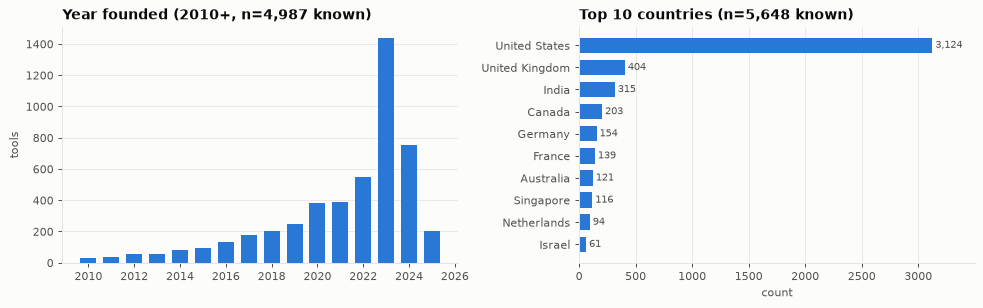

year founded known for 36% of tools; median 2022; 59% founded 2022 or later
country known for 41% of tools; US share of known = 55%


In [9]:
year = kaggle["Year Founded"].dropna()
country = kaggle["Country"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

year_counts = year[year >= 2010].astype(int).value_counts().sort_index()
axes[0].bar(year_counts.index, year_counts.values, color=BLUE, width=0.7)
axes[0].set_title(f"Year founded (2010+, n={len(year):,} known)")
axes[0].set_ylabel("tools")
axes[0].grid(axis="x", visible=False)

barh(country.value_counts().head(10), f"Top 10 countries (n={len(country):,} known)", ax=axes[1])
plt.tight_layout()
plt.show()

print(f"year founded known for {len(year) / len(kaggle):.0%} of tools; median {year.median():.0f}; "
      f"{(year >= 2022).mean():.0%} founded 2022 or later")
print(f"country known for {len(country) / len(kaggle):.0%} of tools; "
      f"US share of known = {(country == 'United States').mean():.0%}")

### A6. Domains in Dataset B

Dataset B's `domain` column (extracted by `convert_kaggle.py`) is what usage logs would be joined on, so check it's a usable key.

In [10]:
dsb = pd.read_csv(DATA / "dataset_b_ai_tool_metadata_incomplete.csv")

print(f"Dataset B rows: {len(dsb):,}")
print(f"blank domains:  {dsb['domain'].isna().sum():,}")
print(f"duplicate domains: {dsb['domain'].duplicated(keep=False).sum():,} rows")

# how many tools live on a shared host (subdomain of a hosting / big-platform site)?
hosts = ["web.app", "vercel.app", "gumroad.com", "github.io", "streamlit.app", "netlify.app",
         "chromewebstore.google.com", "chrome.google.com", "apps.apple.com", "huggingface.co"]
on_host = dsb["domain"].fillna("").apply(lambda d: next((h for h in hosts if d == h or d.endswith("." + h) or d.startswith(h)), None))
print(f"tools hosted on shared platforms: {on_host.notna().sum():,}")
on_host.value_counts().to_frame("tools")

Dataset B rows: 13,701
blank domains:  0
duplicate domains: 4 rows
tools hosted on shared platforms: 272


,tools
domain,
vercel.app,175
gumroad.com,30
github.io,23
netlify.app,22
web.app,12
streamlit.app,10


In [11]:
dsb[dsb["domain"].duplicated(keep=False)][["tool_id", "tool_name", "domain", "category"]]

,tool_id,tool_name,domain,category
26,tool_00027,Hubspot Breeze,hubspot.com,Marketing And Sales
107,tool_00108,Hubspot,hubspot.com,Media And Content Creation
10916,tool_10917,PowerPM,power-pm-ai.web.app,Operations And Management
12416,tool_12417,PowerPM.ai,power-pm-ai.web.app,Operations And Management


### A7. Spot-check: are the categories trustworthy?

Look up well-known tools whose purpose we already know.

In [12]:
known = ["ChatGPT", "Claude", "Google Gemini", "Microsoft Copilot", "Perplexity", "Grammarly",
         "Jasper.ai", "Cursor", "Notion AI", "Slack GPT", "Zoom IQ", "Otter.ai", "Midjourney"]
spot = dsb[dsb["tool_name"].isin(known)][["tool_name", "domain", "category"]]
missing_tools = sorted(set(known) - set(spot["tool_name"]))
print("not in dataset:", missing_tools)
spot.set_index("tool_name").loc[[k for k in known if k in set(spot["tool_name"])]]

not in dataset: ['Midjourney']


,domain,category
tool_name,,
ChatGPT,chatgpt.com,Communication And Support
Claude,claude.ai,Operations And Management
Google Gemini,gemini.google.com,Ai And Machine Learning
Microsoft Copilot,copilot.microsoft.com,Technology And Development
Perplexity,perplexity.ai,Specialized Technologies
Grammarly,grammarly.com,Security And Privacy
Jasper.ai,jasper.ai,Media And Content Creation
Cursor,cursor.so,Technology And Development
Notion AI,notion.so,Media And Content Creation


### A8. Taxonomy gap: Kaggle categories vs. `VISION.md` taxonomy

`VISION.md` (Component 3) proposes a 12-category business-purpose taxonomy. The Kaggle categories are organized differently, so they can't be used as labels as-is. Below is a **proposed** mapping. It's a starting point for team discussion, not a final answer.

In [13]:
vision_taxonomy = [
    "Coding / Developer Tools", "General AI Assistants", "Content Generation", "Image / Video Generation",
    "Meeting / Transcription Tools", "Data Analytics", "Customer Support", "Sales / Marketing",
    "Productivity", "Research / Search", "AI Infrastructure / Model Platforms", "Other",
]

# proposed mapping + how clean it is
mapping = pd.DataFrame([
    ("Media And Content Creation", "Content Generation + Image / Video Generation", "split needed"),
    ("Communication And Support",  "Customer Support + General AI Assistants",       "split needed"),
    ("Technology And Development", "Coding / Developer Tools",                       "mostly clean"),
    ("Operations And Management",  "Productivity",                                   "mostly clean"),
    ("Marketing And Sales",        "Sales / Marketing",                              "clean"),
    ("Ai And Machine Learning",    "AI Infrastructure / Model Platforms",            "mixed (also assistants)"),
    ("Business And Finance",       "Data Analytics / Other",                         "no clear match"),
    ("Specialized Technologies",   "Other",                                          "no clear match"),
    ("Data And Analytics",         "Data Analytics",                                 "clean"),
    ("Creative And Entertainment", "Image / Video Generation",                       "mostly clean"),
    ("Industry Specific",          "Other",                                          "no clear match"),
    ("Education And Learning",     "Research / Search / Other",                      "no clear match"),
    ("Personal And Lifestyle",     "Other",                                          "no clear match"),
    ("Security And Privacy",       "Other",                                          "no clear match"),
], columns=["kaggle_category", "proposed_vision_category", "fit"])

mapping["tools"] = mapping["kaggle_category"].map(cat_counts)
print(mapping.groupby("fit")["tools"].sum().sort_values(ascending=False).to_string())

covered = set()
for target in mapping["proposed_vision_category"]:
    covered.update(t.strip() for t in target.replace(" + ", "|").split("|"))
print("\nVISION categories with no Kaggle source:",
      [c for c in vision_taxonomy if not any(c.split(" /")[0] in t for t in covered)])
mapping

fit
split needed               5125
mostly clean               3206
no clear match             2538
clean                      1763
mixed (also assistants)    1069

VISION categories with no Kaggle source: ['Meeting / Transcription Tools']


,kaggle_category,proposed_vision_category,fit,tools
0,Media And Content Creation,Content Generation + Image / Video Generation,split needed,3530
1,Communication And Support,Customer Support + General AI Assistants,split needed,1595
2,Technology And Development,Coding / Developer Tools,mostly clean,1442
3,Operations And Management,Productivity,mostly clean,1257
4,Marketing And Sales,Sales / Marketing,clean,1150
5,Ai And Machine Learning,AI Infrastructure / Model Platforms,mixed (also assistants),1069
6,Business And Finance,Data Analytics / Other,no clear match,843
7,Specialized Technologies,Other,no clear match,802
8,Data And Analytics,Data Analytics,clean,613
9,Creative And Entertainment,Image / Video Generation,mostly clean,507


---
## Part B: Synthetic enterprise usage logs (Dataset A)

Two fictional companies: **NovaTech** (tech) and **Summit Financial** (finance). Same schema: `event_id, timestamp, employee_id, department, job_role, application_name, domain, event_type, session_duration_seconds, bytes_uploaded, bytes_downloaded`.

To read the charts, each application gets a **reference AI label**. This is my manual judgment of whether the app's core product is an AI tool, used only for EDA. It is *not* the model's output, and it's what Part C checks the metadata against.

In [14]:
usage = pd.concat([
    pd.read_csv(DATA / "novatech_usage (1).csv").assign(company="NovaTech"),
    pd.read_csv(DATA / "summit_financial_usage (1).csv").assign(company="Summit Financial"),
], ignore_index=True)
usage["timestamp"] = pd.to_datetime(usage["timestamp"])

# manual reference label: is the app's core product an AI tool?
AI_APPS = {"ChatGPT", "Claude", "Gemini", "Perplexity", "Cursor", "GitHub Copilot",
           "Jasper", "Midjourney", "Grammarly", "DocuMind AI"}
usage["is_ai_ref"] = usage["application_name"].isin(AI_APPS)

overview = usage.groupby("company").agg(
    events=("event_id", "size"),
    employees=("employee_id", "nunique"),
    departments=("department", "nunique"),
    applications=("application_name", "nunique"),
    ai_apps=("application_name", lambda s: s[s.isin(AI_APPS)].nunique()),
    ai_event_share=("is_ai_ref", "mean"),
    first_event=("timestamp", "min"),
    last_event=("timestamp", "max"),
)
print("missing values in usage logs:", int(usage.isna().sum().sum()))
print("duplicate event_ids:", int(usage["event_id"].duplicated().sum()))
overview["ai_event_share"] = (overview["ai_event_share"] * 100).round(1).astype(str) + "%"
overview

missing values in usage logs: 0
duplicate event_ids: 0


,events,employees,departments,applications,ai_apps,ai_event_share,first_event,last_event
company,,,,,,,,
NovaTech,30000,500,6,21,9,39.8%,2026-09-01 08:00:00,2026-09-30 18:59:00
Summit Financial,25120,400,6,22,10,20.5%,2026-09-01 08:00:00,2026-09-30 18:59:00


### B1. Who generates the activity?

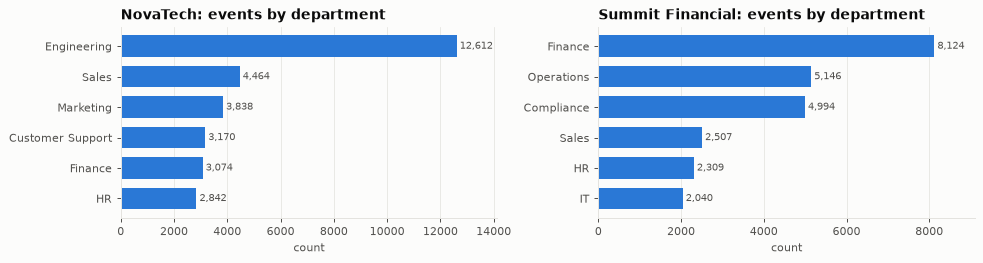

employees  events  events_per_employee
company          department                                              
NovaTech         Customer Support         55    3170                 57.6
                 Engineering             207   12612                 60.9
                 Finance                  51    3074                 60.3
                 HR                       48    2842                 59.2
                 Marketing                65    3838                 59.0
                 Sales                    74    4464                 60.3
Summit Financial Compliance               79    4994                 63.2
                 Finance                 129    8124                 63.0
                 HR                       37    2309                 62.4
                 IT                       33    2040                 61.8
                 Operations               82    5146                 62.8
                 Sales                    40    2507                 62.7

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, (company, g) in zip(axes, usage.groupby("company")):
    barh(g["department"].value_counts(), f"{company}: events by department", ax=ax)
plt.tight_layout()
plt.show()

per_emp = usage.groupby(["company", "department"]).agg(employees=("employee_id", "nunique"), events=("event_id", "size"))
per_emp["events_per_employee"] = (per_emp["events"] / per_emp["employees"]).round(1)
per_emp

### B2. Which applications? (blue = AI tool by reference label)

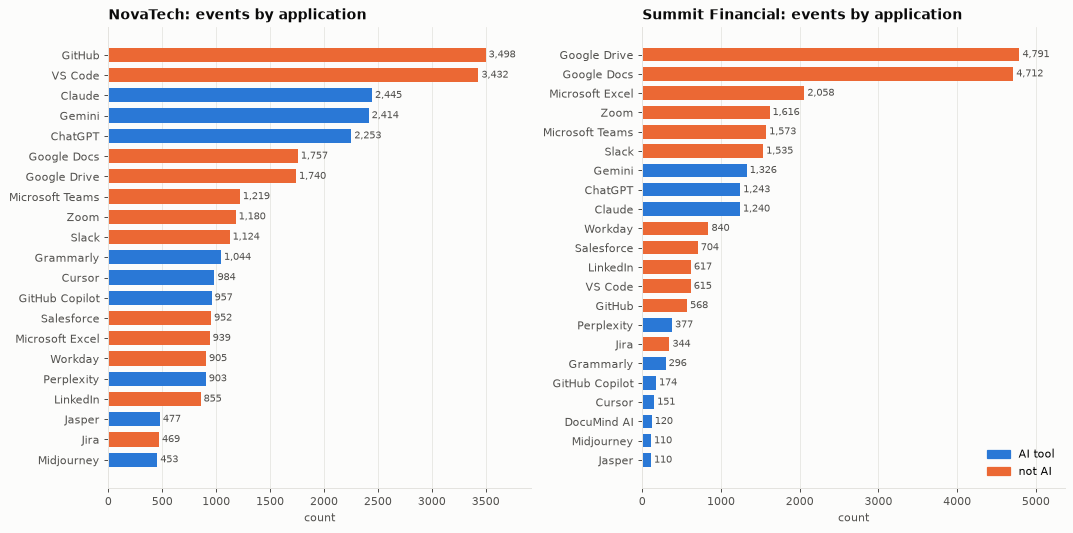

apps only at NovaTech:         []
apps only at Summit Financial: ['DocuMind AI']


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (company, g) in zip(axes, usage.groupby("company")):
    counts = g["application_name"].value_counts().sort_values()
    colors = [BLUE if a in AI_APPS else ORANGE for a in counts.index]
    barh(counts, f"{company}: events by application", ax=ax, color=colors)
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
               labels=["AI tool", "not AI"], loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

apps_by_company = usage.groupby(["application_name", "company"]).size().unstack(fill_value=0)
print("apps only at NovaTech:        ", sorted(apps_by_company.index[apps_by_company["Summit Financial"] == 0]))
print("apps only at Summit Financial:", sorted(apps_by_company.index[apps_by_company["NovaTech"] == 0]))

### B3. Event types

In [17]:
pd.crosstab(usage["event_type"], usage["company"], normalize="columns").mul(100).round(1).add_suffix(" (%)")

company,NovaTech (%),Summit Financial (%)
event_type,,
application_open,25.3,24.3
application_session,24.7,25.5
browser_visit,25.2,25.7
login,24.7,24.5


### B4. Time patterns

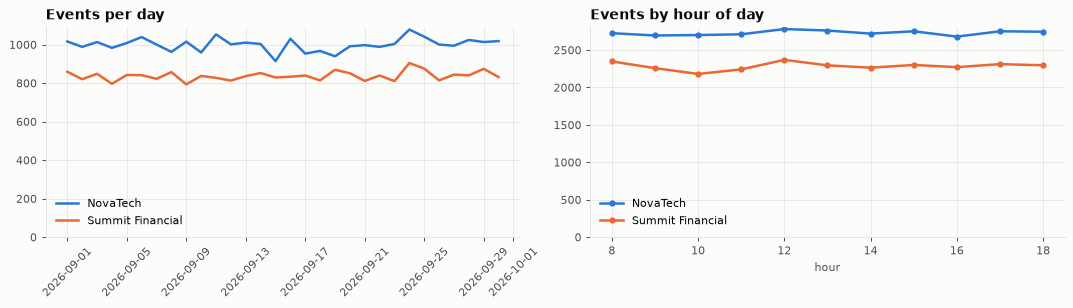

events by weekday: {'Tuesday': 9151, 'Wednesday': 9141, 'Thursday': 7431, 'Sunday': 7406, 'Friday': 7356, 'Monday': 7349, 'Saturday': 7286}
hours covered: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
weekend share of events: 27% (weekends are 8 of 30 days = 27%)


In [18]:
daily = usage.groupby([usage["timestamp"].dt.date, "company"]).size().unstack()
hourly = usage.groupby([usage["timestamp"].dt.hour, "company"]).size().unstack()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for company, color in [("NovaTech", BLUE), ("Summit Financial", ORANGE)]:
    axes[0].plot(daily.index, daily[company], color=color, linewidth=2, label=company)
    axes[1].plot(hourly.index, hourly[company], color=color, linewidth=2, marker="o", markersize=4, label=company)
axes[0].set_title("Events per day")
axes[0].tick_params(axis="x", rotation=45)
axes[1].set_title("Events by hour of day")
axes[1].set_xlabel("hour")
for ax in axes:
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

weekday = usage["timestamp"].dt.day_name().value_counts()
print("events by weekday:", weekday.to_dict())
print("hours covered:", sorted(int(h) for h in usage["timestamp"].dt.hour.unique()))
print("weekend share of events:", f"{usage['timestamp'].dt.dayofweek.ge(5).mean():.0%}", "(weekends are 8 of 30 days = 27%)")

### B5. Session duration

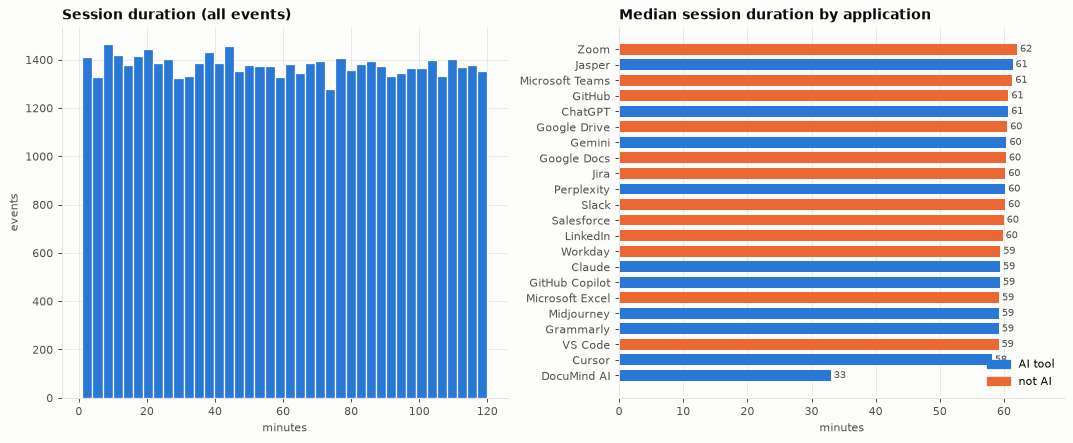

count    55120.0
mean      3612.0
std       2065.0
min         60.0
25%       1818.0
50%       3603.0
75%       5397.0
max       7200.0

median minutes, AI vs not: {False: 60.2, True: 59.6}


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(usage["session_duration_seconds"] / 60, bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[0].set_title("Session duration (all events)")
axes[0].set_xlabel("minutes")
axes[0].set_ylabel("events")

med = usage.groupby("application_name")["session_duration_seconds"].median().div(60)
barh(med, "Median session duration by application", xlabel="minutes", ax=axes[1],
     color=[BLUE if a in AI_APPS else ORANGE for a in med.sort_values().index], fmt="{:.0f}")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
               labels=["AI tool", "not AI"], loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

print(usage["session_duration_seconds"].describe().round(0).to_string())
print("\nmedian minutes, AI vs not:", usage.groupby("is_ai_ref")["session_duration_seconds"].median().div(60).round(1).to_dict())

### B6. Data transfer (`bytes_uploaded` / `bytes_downloaded`)

Upload volume is the closest thing in the logs to "how much company data is being sent to a tool", which is a direct data-leakage signal for risk scoring.

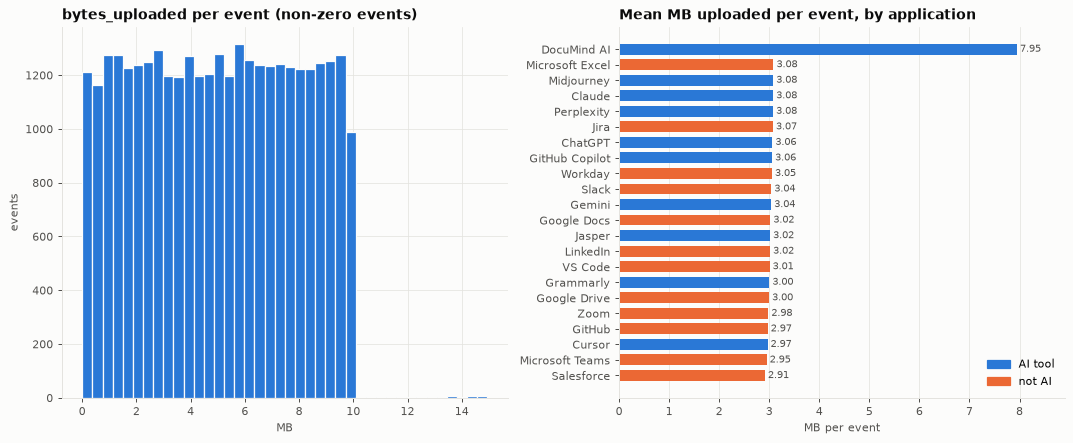

max single upload: 14.9 MB overall; apps with any upload > 10 MB: ['DocuMind AI']
events with 0 bytes uploaded:   40%
events with 0 bytes downloaded: 30%
correlation upload vs session duration: -0.01

median MB uploaded per event, by event type:
event_type
application_open       1.64
application_session    1.74
browser_visit          1.82
login                  1.64

mean MB uploaded per event, by department:
company           department      
NovaTech          Customer Support    3.04
                  Engineering         3.02
                  Finance             3.07
                  HR                  2.96
                  Marketing           3.07
                  Sales               3.02
Summit Financial  Compliance          2.93
                  Finance             3.14
                  HR                  2.92
                  IT                  2.95
                  Operations          3.07
                  Sales               2.98


,events,pct_events_uploading,mean_mb_up,mean_mb_down,total_gb_up
is_ai_ref,,,,,
non-AI apps,38043,60.2,3.00,7.03,114.3
AI tools,17077,60.4,3.08,6.97,52.6


In [20]:
MB = 1_000_000
up = usage["bytes_uploaded"] / MB

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(up[up > 0], bins=40, color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[0].set_title("bytes_uploaded per event (non-zero events)")
axes[0].set_xlabel("MB")
axes[0].set_ylabel("events")

# mean per event, not total: a rarely used tool can still be uploading unusually large payloads
up_app = usage.groupby("application_name")["bytes_uploaded"].mean() / MB
barh(up_app, "Mean MB uploaded per event, by application", xlabel="MB per event", ax=axes[1],
     color=[BLUE if a in AI_APPS else ORANGE for a in up_app.sort_values().index], fmt="{:.2f}")
axes[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
               labels=["AI tool", "not AI"], loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

print(f"max single upload: {usage['bytes_uploaded'].max() / MB:.1f} MB overall; apps with any upload > 10 MB: "
      f"{sorted(usage.loc[usage['bytes_uploaded'] > 10 * MB, 'application_name'].unique())}")
print(f"events with 0 bytes uploaded:   {(usage['bytes_uploaded'] == 0).mean():.0%}")
print(f"events with 0 bytes downloaded: {(usage['bytes_downloaded'] == 0).mean():.0%}")
print(f"correlation upload vs session duration: {usage['bytes_uploaded'].corr(usage['session_duration_seconds']):.2f}")
print("\nmedian MB uploaded per event, by event type:")
print(usage.groupby("event_type")["bytes_uploaded"].median().div(MB).round(2).to_string())
print("\nmean MB uploaded per event, by department:")
print(usage.groupby(["company", "department"])["bytes_uploaded"].mean().div(MB).round(2).to_string())

transfer = usage.groupby("is_ai_ref").agg(
    events=("event_id", "size"),
    pct_events_uploading=("bytes_uploaded", lambda s: round((s > 0).mean() * 100, 1)),
    mean_mb_up=("bytes_uploaded", lambda s: round(s.mean() / MB, 2)),
    mean_mb_down=("bytes_downloaded", lambda s: round(s.mean() / MB, 2)),
    total_gb_up=("bytes_uploaded", lambda s: round(s.sum() / 1e9, 1)),
).rename(index={True: "AI tools", False: "non-AI apps"})
transfer

### B7. Department × application

Share of each department's events going to each app. This is the "which departments use which tools" view the governance dashboard needs.

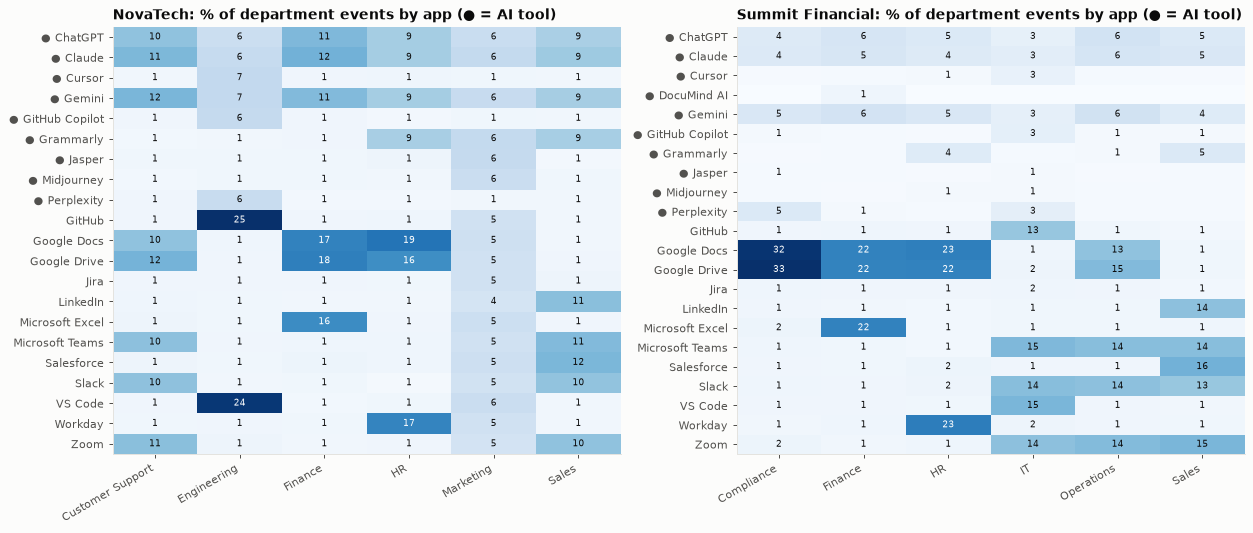

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (company, g) in zip(axes, usage.groupby("company")):
    share = pd.crosstab(g["application_name"], g["department"], normalize="columns") * 100
    order = sorted(share.index, key=lambda a: (a not in AI_APPS, a))   # AI apps first
    share = share.loc[order]
    im = ax.imshow(share.values, cmap="Blues", aspect="auto", vmin=0)
    ax.set_xticks(range(share.shape[1]), share.columns, rotation=30, ha="right")
    ax.set_yticks(range(share.shape[0]), [("● " if a in AI_APPS else "") + a for a in share.index])
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            v = share.values[i, j]
            if v >= 0.5:
                ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                        color="white" if v > share.values.max() * 0.6 else INK)
    ax.set_title(f"{company}: % of department events by app (● = AI tool)")
    ax.grid(False)
plt.tight_layout()
plt.show()

---
## Part C: Cross-dataset (does usage line up with the metadata?)

The simplest discovery approach is the *known-tool lookup* from `VISION.md`: join each observed `domain` to Dataset B. Since every Dataset B row has `is_ai_tool = True`, a match means "this is an AI tool". How well does that work against the reference label?

In [22]:
apps = (usage.groupby(["application_name", "domain"])
             .agg(events=("event_id", "size"), employees=("employee_id", "nunique"))
             .reset_index())
apps["is_ai_ref"] = apps["application_name"].isin(AI_APPS)

# domain lookup
dom_to_tool = dsb.drop_duplicates("domain").set_index("domain")["tool_name"]
apps["domain_match"] = apps["domain"].map(dom_to_tool)

# exact name lookup (case-insensitive) as a second approach
name_to_domain = dsb.assign(n=dsb["tool_name"].str.lower()).drop_duplicates("n").set_index("n")["domain"]
apps["name_match_domain"] = apps["application_name"].str.lower().map(name_to_domain)

apps.sort_values(["is_ai_ref", "events"], ascending=[False, False]).reset_index(drop=True)

,application_name,domain,events,employees,is_ai_ref,domain_match,name_match_domain
0,Gemini,gemini.google.com,3740,869,True,Google Gemini,NaN
1,Claude,claude.ai,3685,870,True,Claude,claude.ai
2,ChatGPT,chatgpt.com,3496,872,True,ChatGPT,chatgpt.com
3,Grammarly,grammarly.com,1340,464,True,Grammarly,grammarly.com
4,Perplexity,perplexity.ai,1280,479,True,Perplexity,perplexity.ai
5,Cursor,cursor.com,1135,443,True,NaN,cursor.so
6,GitHub Copilot,github.com/copilot,1131,438,True,NaN,NaN
7,Jasper,jasper.ai,587,343,True,Jasper.ai,NaN
8,Midjourney,midjourney.com,563,355,True,NaN,NaN
9,DocuMind AI,documind-ai.com,120,84,True,NaN,NaN


In [23]:
def lookup_scores(found):
    tp = (found & apps["is_ai_ref"]).sum()
    fp = (found & ~apps["is_ai_ref"]).sum()
    fn = (~found & apps["is_ai_ref"]).sum()
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    return {"AI found (TP)": tp, "non-AI flagged (FP)": fp, "AI missed (FN)": fn,
            "precision": round(precision, 2), "recall": round(recall, 2)}

pd.DataFrame({
    "domain lookup": lookup_scores(apps["domain_match"].notna()),
    "name lookup": lookup_scores(apps["name_match_domain"].notna()),
    "domain OR name": lookup_scores(apps["domain_match"].notna() | apps["name_match_domain"].notna()),
}).T

,AI found (TP),non-AI flagged (FP),AI missed (FN),precision,recall
domain lookup,6.0,3.0,4.0,0.67,0.6
name lookup,5.0,0.0,5.0,1.00,0.5
domain OR name,7.0,3.0,3.0,0.70,0.7


**Why the lookup fails both ways:**

In [24]:
fp = apps[apps["domain_match"].notna() & ~apps["is_ai_ref"]][["application_name", "domain", "domain_match"]]
fp.columns = ["usage app (not AI)", "domain", "Dataset B tool on that domain"]
print("FALSE POSITIVES: a non-AI platform shares its domain with an AI feature/add-on listed in Kaggle")
display(fp)

fn = apps[apps["domain_match"].isna() & apps["is_ai_ref"]][["application_name", "domain", "name_match_domain", "events", "employees"]]
fn.columns = ["usage app (AI)", "usage domain", "Dataset B domain for same name", "events", "employees"]
print("FALSE NEGATIVES: AI tools in use that the domain lookup misses (the 'unseen tool' case)")
display(fn)

FALSE POSITIVES: a non-AI platform shares its domain with an AI feature/add-on listed in Kaggle


,usage app (not AI),domain,Dataset B tool on that domain
5,GitHub,github.com,RootKit - AI Aimbot
18,Slack,slack.com,Slack GPT
21,Zoom,zoom.us,Zoom IQ


FALSE NEGATIVES: AI tools in use that the domain lookup misses (the 'unseen tool' case)


,usage app (AI),usage domain,Dataset B domain for same name,events,employees
2,Cursor,cursor.com,cursor.so,1135,443
3,DocuMind AI,documind-ai.com,NaN,120,84
6,GitHub Copilot,github.com/copilot,NaN,1131,438
15,Midjourney,midjourney.com,NaN,563,355


### C1. AI adoption by department

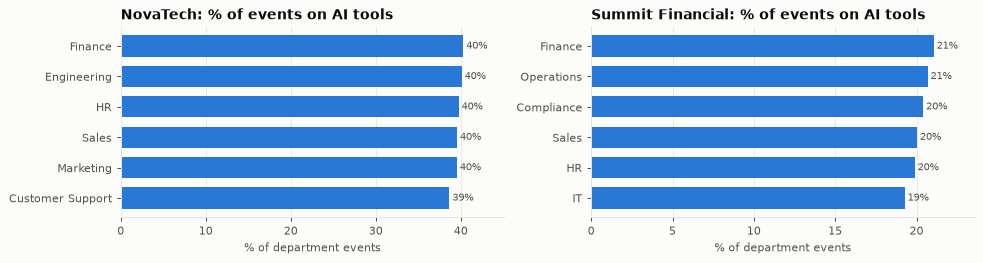

% of employees using >=1 AI tool, per department: min 100%, max 100%
company-wide AI share of events: {'NovaTech': 39.8, 'Summit Financial': 20.5}


In [25]:
dept_ai = usage.groupby(["company", "department"])["is_ai_ref"].mean().mul(100)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, company in zip(axes, ["NovaTech", "Summit Financial"]):
    barh(dept_ai[company], f"{company}: % of events on AI tools", xlabel="% of department events", ax=ax, fmt="{:.0f}%")
plt.tight_layout()
plt.show()

emp_ai = (usage[usage["is_ai_ref"]].groupby(["company", "department"])["employee_id"].nunique()
          / usage.groupby(["company", "department"])["employee_id"].nunique() * 100)
print(f"% of employees using >=1 AI tool, per department: min {emp_ai.min():.0f}%, max {emp_ai.max():.0f}%")
print("company-wide AI share of events:", usage.groupby("company")["is_ai_ref"].mean().mul(100).round(1).to_dict())

### C2. AI tools in sensitive departments

Finance, HR and Compliance handle the most sensitive data, which makes them a key risk factor in `VISION.md` Component 4.

In [26]:
SENSITIVE = ["Finance", "HR", "Compliance"]
sens = usage[usage["is_ai_ref"] & usage["department"].isin(SENSITIVE)]

sens_table = (sens.groupby(["company", "department", "application_name"])
                  .agg(employees=("employee_id", "nunique"), events=("event_id", "size"),
                       gb_uploaded=("bytes_uploaded", lambda s: round(s.sum() / 1e9, 2)))
                  .reset_index()
                  .sort_values(["company", "department", "employees"], ascending=[True, True, False]))
sens_table["in Dataset B (by domain)"] = sens_table["application_name"].map(apps.set_index("application_name")["domain_match"].notna())
sens_table

,company,department,application_name,employees,events,gb_uploaded,in Dataset B (by domain)
1,NovaTech,Finance,Claude,51,373,1.26,True
3,NovaTech,Finance,Gemini,51,342,1.10,True
0,NovaTech,Finance,ChatGPT,50,350,1.03,True
5,NovaTech,Finance,Grammarly,29,33,0.08,True
7,NovaTech,Finance,Midjourney,25,28,0.09,False
4,NovaTech,Finance,GitHub Copilot,24,31,0.09,False
2,NovaTech,Finance,Cursor,23,33,0.07,False
6,NovaTech,Finance,Jasper,22,28,0.06,True
8,NovaTech,Finance,Perplexity,16,20,0.05,True
9,NovaTech,HR,ChatGPT,48,254,0.74,True


In [27]:
# unknown-to-metadata AI tools reaching sensitive departments: the highest-priority investigation targets
unseen = sens_table[~sens_table["in Dataset B (by domain)"]]
display(unseen.groupby("application_name")[["employees", "events", "gb_uploaded"]].sum().sort_values("employees", ascending=False))

# DocuMind AI only appears at Summit Financial: who is using it?
documind = usage[usage["application_name"] == "DocuMind AI"]
finance_size = usage[(usage["company"] == "Summit Financial") & (usage["department"] == "Finance")]["employee_id"].nunique()
print(f"DocuMind AI: {documind['employee_id'].nunique()} of {finance_size} Summit Financial Finance employees, "
      f"departments = {sorted(documind['department'].unique())}, first seen {documind['timestamp'].min():%Y-%m-%d}")
print(f"DocuMind AI uploads: {documind['bytes_uploaded'].sum() / 1e9:.2f} GB total, "
      f"mean {documind['bytes_uploaded'].mean() / 1e6:.2f} MB/event vs {usage['bytes_uploaded'].mean() / 1e6:.2f} MB/event overall")
documind["job_role"].value_counts().to_frame("events")

,employees,events,gb_uploaded
application_name,,,
Midjourney,107,117,0.35
GitHub Copilot,101,121,0.31
Cursor,99,130,0.36
DocuMind AI,84,120,0.95


DocuMind AI: 84 of 129 Summit Financial Finance employees, departments = ['Finance'], first seen 2026-09-04
DocuMind AI uploads: 0.95 GB total, mean 7.95 MB/event vs 3.03 MB/event overall


,events
job_role,
Accountant,58
Financial Analyst,33
Finance Manager,29


---
## Part D: Key findings

**Kaggle tool metadata**
1. **Most metadata columns are sparse.** Year Founded is missing for 64% of tools, Country 59%, technologies 53%, industry 52% and Keywords 40%. `Name`, `Short Description`, `Category`, `Primary Task` and `Website` are the only complete fields, so models and risk rules should be built on those and not depend on the sparse ones.
2. **Descriptions are short.** The median is 8 words, and 17% of tools have 5 words or fewer (e.g. "Images", "Sales"). Embeddings of the description alone will be weak for those tools. Concatenating `Name + Short Description + Primary Task (+ Keywords when present)` is a cheap way to enrich the text.
3. **Categories are imbalanced and noisy.** Media & Content Creation covers 26% of tools, 21× the smallest category. Well-known tools are miscategorized: ChatGPT is "Communication And Support", Claude "Operations And Management", Grammarly "Security And Privacy", Perplexity "Specialized Technologies". About 2,500 tools sit in categories with no clear match to the `VISION.md` taxonomy, and *Meeting / Transcription* has no source category at all. The Kaggle `Category` field shouldn't be treated as clean ground truth. It needs a mapping plus a hand-labeled evaluation subset. `Primary Task` isn't a usable label either: 2,973 distinct values, 60% of them used once.
4. **Dataset B has no negative class.** Every row is `is_ai_tool = True`. Training or evaluating AI-vs-not-AI detection needs non-AI SaaS examples, such as the Slack, Workday and Salesforce-type apps in the usage logs.

**Synthetic usage logs**

5. **The logs are clean but very uniform.** There are no missing values or duplicate IDs. Event types are each about 25%. Session durations are uniform between 1 and 120 minutes regardless of app. Weekends are as busy as weekdays, and volume is flat across hours. Every employee in every department uses at least one AI tool. Uploads are uniform between 0 and 10 MB, 40% of events upload nothing, and upload size is unrelated to session length (r = −0.01). Average upload per event is the same for AI and non-AI apps (about 3 MB). Background usage therefore carries little signal. The meaningful signals are the department × application mix and outliers against that flat baseline.
6. **There is a clear planted shadow-AI scenario.** NovaTech sends about 40% of events to AI tools and Summit Financial about 21%. **DocuMind AI** stands out on every axis:
   - it appears only at Summit Financial, only in **Finance** (84 of 129 employees, mostly Accountants and Financial Analysts);
   - it isn't in the metadata;
   - it uploads **7.95 MB per event, 2.6× every other app** (about 3 MB);
   - it **never** has a zero-byte upload, and it's the **only app with uploads over 10 MB**;
   - its median session is 33 minutes, against about 60 minutes elsewhere.

   This matches the `VISION.md` §4 "new unapproved AI tool handling uploaded documents in Finance" example. Upload volume relative to the baseline should be a core risk-scoring feature.

**Cross-dataset**

7. **A known-tool domain lookup isn't enough.** Against the reference labels it gets precision 0.67 and recall 0.60.
   - *False positives* come from platforms that host AI add-ons on the same domain: `slack.com` → "Slack GPT", `zoom.us` → "Zoom IQ", and `github.com` → "RootKit - AI Aimbot".
   - *Misses* come from stale domains (Cursor is `cursor.so` in Kaggle, `cursor.com` in usage), path-based domains (`github.com/copilot`), and tools absent from Kaggle (Midjourney, DocuMind AI).
   - So we need domain normalization (strip paths, handle renames) and a semantic/embedding or LLM step for unseen tools, which is exactly what `VISION.md` Component 2 asks for. Four AI tools reach sensitive departments (Finance, HR, Compliance) without matching the metadata: Midjourney, GitHub Copilot, Cursor and DocuMind AI (84–107 employees each).